# Fase 3: Modelagem, Protocolo Experimental e Inferência Estatística

Este notebook implementa a experimentação rigorosa para a previsão e classificação do nível de risco criminal (Alto/Baixo) no entorno do campus do **IFSP-SPO**.

O pipeline foi arquitetado em estrita conformidade com os passos metodológicos do enunciado acadêmico e as diretrizes de reprodutibilidade da conferência **ACL 2023**:

1. **Passo 1:** Testes de sanidade e consistência estrutural nos 4 modelos supervisionados;
2. **Passo 2:** Definição da população-alvo e particionamento temporal cronológico;
3. **Passos 3 e 4:** Treinamento, validação e replicação Monte Carlo com 30 sementes aleatórias (42 a 71) e salvamento de 120 checkpoints;
4. **Passo 5:** Análise estatística formal (Intervalos de Confiança a 95%, Teste Omnibus de Friedman e Teste Post-Hoc de Wilcoxon com correção de Holm-Bonferroni);
5. **Passo 6:** Avaliação da generalização em dados não vistos (2026), confronto contra baseline da classe majoritária e auditoria de *Concept Drift*;
6. **Passo 7:** Treinamento e serialização do artefato definitivo para deploy (100% dos dados).

## 1. Importação de Bibliotecas e Módulos do Projeto

In [1]:
import os
import sys
from pathlib import Path

# Adiciona o diretório raiz ao PYTHONPATH para importar o pacote modules
root_path = Path.cwd().parent
if str(root_path) not in sys.path:
    sys.path.insert(0, str(root_path))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from modules.config import (
    BASE_RANDOM_SEED,
    DATA_PROCESSED_DIR,
    DEV_TEST_SPLIT_RATIO,
    FINAL_MODEL_NAME,
    MODELS_FINAL_DIR,
    N_EXPERIMENT_ITERATIONS,
    PROCESSED_DATASET_NAME,
)
from modules.features import apply_risk_threshold_without_leakage, split_dev_test_chronological
from modules.modeling.evaluation import (
    analyze_concept_drift,
    compute_confidence_intervals,
    evaluate_unseen_data,
    run_friedman_test,
    run_posthoc_wilcoxon,
)
from modules.modeling.predict import format_risk_prediction, load_model
from modules.modeling.train import (
    get_model_constructors,
    run_experiments,
    run_sanity_check,
    train_final_model,
)
from modules.plots import plot_confidence_intervals, plot_confusion_matrix, plot_f1_distributions

sns.set_theme(style="whitegrid")
print("Ambiente e módulos do projeto importados com sucesso.")

Ambiente e módulos do projeto importados com sucesso.


## 2. Carga dos Dados Processados e Particionamento Temporal Estrito

Para assegurar integridade metodológica absoluta e evitar qualquer vazamento de dados (*data leakage*):
* Os **85% iniciais** da série cronológica (2022 a início de 2026) são destinados ao conjunto de **Desenvolvimento** ($X_{dev}, y_{dev}$);
* Os **15% finais** (2026) são isolados estritamente para o **Passo 6** (teste de generalização em dados não vistos);
* O limiar da mediana de crimes por janela é **calculado estritamente sobre $y_{dev}$**, garantindo zero vazamento da distribuição futura.

In [2]:
# Carregar dataset pré-processado
df_processed = pd.read_csv(DATA_PROCESSED_DIR / PROCESSED_DATASET_NAME, sep=";")

# Particionamento temporal estrito
df_dev_raw, df_test_raw = split_dev_test_chronological(df_processed, split_ratio=DEV_TEST_SPLIT_RATIO)

# Aplicação do limiar de risco sem vazamento de alvo
df_dev, df_test, threshold = apply_risk_threshold_without_leakage(df_dev_raw, df_test_raw)

# Matriz de atributos dinâmicos e causais
period_dummies = [c for c in df_processed.columns if c.startswith("PERIODO_") and c != "PERIODO_LETIVO_IFSP"]
feature_cols = [
    "ANO",
    "MES",
    "DIA_SEMANA",
    "FLAG_FIM_DE_SEMANA",
    "TRIMESTRE",
    "PERIODO_LETIVO_IFSP",
    "CRIMES_LAG_1",
    "CRIMES_LAG_4",
    "CRIMES_MEDIA_MOVEL_7D",
] + period_dummies

X_dev = df_dev[feature_cols]
y_dev = df_dev["RISCO_ALTO"]
X_test = df_test[feature_cols]
y_test = df_test["RISCO_ALTO"]

print(f"Tamanho Desenvolvimento: {len(X_dev)} janelas (limiar de Risco Alto > {threshold:.1f} crimes)")
print(f"Tamanho Teste Final:     {len(X_test)} janelas (isolado até o Passo 6)")
print(f"Features dinâmicas ({len(feature_cols)}): {feature_cols}")

Tamanho Desenvolvimento: 5899 janelas (limiar de Risco Alto > 4.0 crimes)
Tamanho Teste Final:     1041 janelas (isolado até o Passo 6)
Features dinâmicas (13): ['ANO', 'MES', 'DIA_SEMANA', 'FLAG_FIM_DE_SEMANA', 'TRIMESTRE', 'PERIODO_LETIVO_IFSP', 'CRIMES_LAG_1', 'CRIMES_LAG_4', 'CRIMES_MEDIA_MOVEL_7D', 'PERIODO_MADRUGADA', 'PERIODO_MANHÃ', 'PERIODO_NOITE', 'PERIODO_TARDE']


## Passo 1 do Enunciado: Teste de Sanidade e Consistência (Todos os 4 Modelos)

Validação antecipada da implementação dos **4 classificadores supervisionados** sobre uma amostra reduzida (30 instâncias):
1. Checagem de compatibilidade de shapes e dimensões;
2. Verificação de ausência de nulos/inconsistências;
3. Capacidade de convergência e aprendizado supervisionado (overfit proposital da árvore sem poda).

In [3]:
models = get_model_constructors()
X_sanity = X_dev.iloc[:30].copy()
y_sanity = y_dev.iloc[:30].copy()

sanity_results = run_sanity_check(models, X_sanity, y_sanity)

for model_name, acc in sanity_results.items():
    print(f"[Sanidade OK] {model_name:<20}: Acurácia no subconjunto = {acc*100:.1f}%")
print("Implementações validadas com sucesso para todos os 4 algoritmos.")

[Sanidade OK] Logistic Regression : Acurácia no subconjunto = 86.7%
[Sanidade OK] Decision Tree       : Acurácia no subconjunto = 100.0%
[Sanidade OK] Random Forest       : Acurácia no subconjunto = 100.0%
[Sanidade OK] Gradient Boosting   : Acurácia no subconjunto = 100.0%
Implementações validadas com sucesso para todos os 4 algoritmos.


## Passos 3 e 4 do Enunciado: Execução e Replicação Experimental (30 Sementes)

Execução de 30 iterações com particionamento Monte Carlo estratificado ($80/20$) dentro de $X_{dev}$ variando sementes de $42$ a $71$.
Todos os 120 pesos treinados são salvos em `models/checkpoints/` acompanhados do registro tabular de métricas em `log_experimentos.csv`.

In [4]:
df_results = run_experiments(
    models,
    X_dev,
    y_dev,
    n_iterations=N_EXPERIMENT_ITERATIONS,
    base_seed=BASE_RANDOM_SEED,
)

print(f"{len(df_results)} experimentos concluídos e checkpoints salvos em models/checkpoints/.")
df_results.head()

120 experimentos concluídos e checkpoints salvos em models/checkpoints/.
Out[0]: 
                Modelo  Seed  F1_Score  Acuracia  Precisao    Recall
0  Logistic Regression    42  0.707018  0.716949  0.713274  0.700870
1        Decision Tree    42  0.737449  0.729661  0.700000  0.779130
2        Random Forest    42  0.716392  0.722881  0.714533  0.718261
3    Gradient Boosting    42  0.724490  0.725424  0.708819  0.740870
4  Logistic Regression    43  0.692174  0.700000  0.692174  0.692174


## Passo 5 do Enunciado: Análise Estatística Formal dos Resultados

Conforme as diretrizes da ACL 2023 e recomendações clássicas de avaliação comparativa de algoritmos de aprendizado (Demšar, 2006):
1. **Intervalos de Confiança a 95%:** Calculados via distribuição $t$ de Student ($gl = 29$) para F1-Score e Acurácia;
2. **Teste Omnibus de Friedman:** Teste não-paramétrico pareado para avaliar se há diferença significativa entre múltiplos classificadores;
3. **Teste Post-Hoc Pareado de Wilcoxon com Correção de Holm-Bonferroni:** Identifica quais pares de modelos diferem com controle estrito da taxa de erro familiar (FWER);
4. **Princípio da Parcimônia (Navalha de Occam):** Análise da relação custo-benefício entre explicabilidade (Árvore de Decisão) e complexidade de ensemble (Gradient Boosting).

                Modelo     Média  ...  IC_95%_Sup   Mediana
0    Gradient Boosting  0.730730  ...    0.736039  0.730835
1        Decision Tree  0.728108  ...    0.733101  0.729508
2        Random Forest  0.722163  ...    0.727257  0.721176
3  Logistic Regression  0.699577  ...    0.704195  0.703831

[4 rows x 6 columns]
Teste de Friedman: Estatística = 63.5200, p-valor = 1.0396e-13
Rejeita-se H0: existe superioridade estatisticamente significante entre os classificadores.

                                 Comparação  ...  Significante_5%
0      Decision Tree vs Logistic Regression  ...             True
1  Gradient Boosting vs Logistic Regression  ...             True
2      Logistic Regression vs Random Forest  ...             True
3        Gradient Boosting vs Random Forest  ...             True
4            Decision Tree vs Random Forest  ...             True
5        Decision Tree vs Gradient Boosting  ...            False

[6 rows x 6 columns]
Modelo com maior pontuação média: Grad

Fallback to a different backend
D:\Documentos\Github\spoincd-projeto-final\modules\plots.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
<ipython-input-1-173ed194f754>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
<ipython-input-1-173ed194f754>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


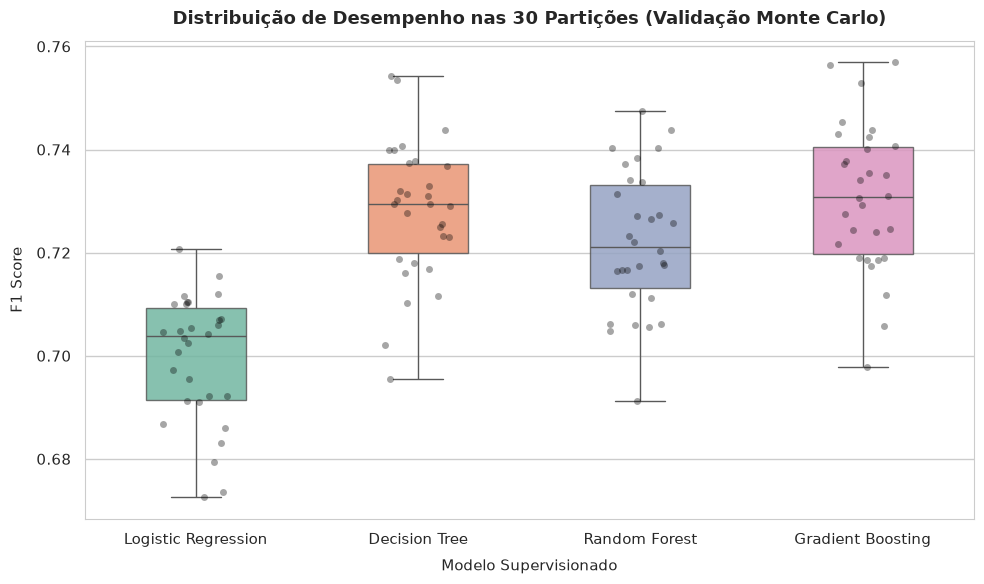

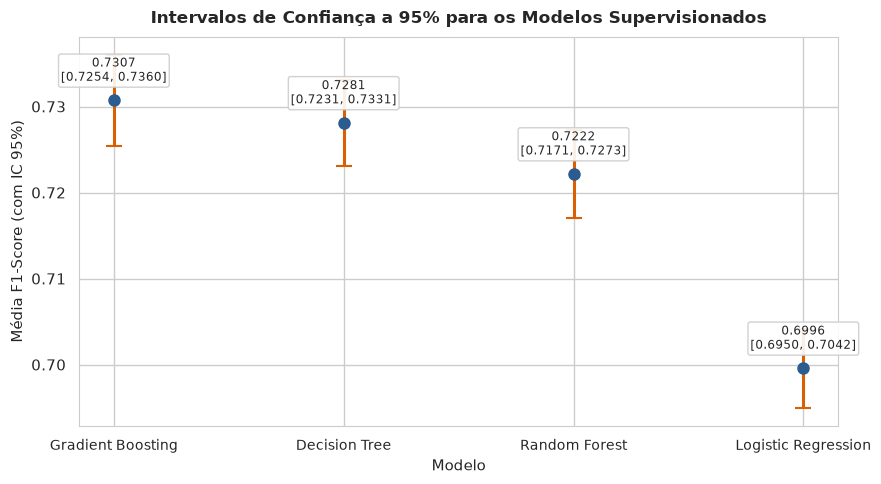

In [5]:
# 1. Intervalos de Confiança (95%)
df_ci = compute_confidence_intervals(df_results, metric="F1_Score", confidence=0.95)
display(df_ci[["Modelo", "Média", "Desvio_Padrão", "IC_95%_Inf", "IC_95%_Sup", "Mediana"]])

# Visualizações estatísticas
fig_box = plot_f1_distributions(df_results, metric="F1_Score")
plt.show()

fig_ci = plot_confidence_intervals(df_ci, metric_label="F1-Score")
plt.show()

# 2. Teste Omnibus de Friedman
stat_f, p_f, is_sig_f = run_friedman_test(df_results, metric="F1_Score")
print(f"Teste de Friedman: Estatística = {stat_f:.4f}, p-valor = {p_f:.4e}")
if is_sig_f:
    print("Rejeita-se H0: existe superioridade estatisticamente significante entre os classificadores.\n")

# 3. Teste Post-Hoc Pareado de Wilcoxon com Ajuste de Holm
df_posthoc = run_posthoc_wilcoxon(df_results, metric="F1_Score", alpha=0.05)
display(df_posthoc[["Comparação", "Diferença_Média (A - B)", "Vitórias_A", "Vitórias_B", "p_valor_ajustado_Holm", "Significante_5%"]])

# 4. Avaliação de Parcimônia
best_model_name = df_ci.iloc[0]["Modelo"]
print(f"Modelo com maior pontuação média: {best_model_name}")

## Passo 6 do Enunciado: Estimativa de Erro em Dados Não Vistos e Auditoria de Concept Drift

O modelo vencedor é treinado sobre **todo o conjunto de desenvolvimento** ($X_{dev}$) e testado exclusivamente no conjunto **$X_{test}$** (15% finais correspondentes ao ano de 2026).

Comparamos seu desempenho com o baseline ingênuo da classe majoritária (*DummyClassifier*) e auditamos a taxa de criminalidade para quantificar o fenômeno de **Concept Drift** (deslocamento temporal da distribuição).

=== DESEMPENHO EM DADOS NÃO VISTOS (2026) ===
Modelo: Gradient Boosting
  Acurácia:                 76.85%
  F1-Score:                 0.2251
  Precisão (Classe Risco):  48.61%
  Recall (Classe Risco):    14.64%
  ROC-AUC:                  0.7871

=== CONFRONTO COM O BASELINE DA CLASSE MAJORITÁRIA ===
  Acurácia Baseline Dummy:  77.04%
  F1-Score Baseline Dummy:  0.0000

=== AUDITORIA DE CONCEPT DRIFT ===
Volume médio de crimes/janela em Dev (2022-2025):  5.01
Volume médio de crimes/janela em Teste (2026):     2.84
Variação na densidade criminal:                     -43.4%
Prevalência de Risco Alto:                          Dev=48.7% vs Teste=23.0%


<ipython-input-1-130fff363b61>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


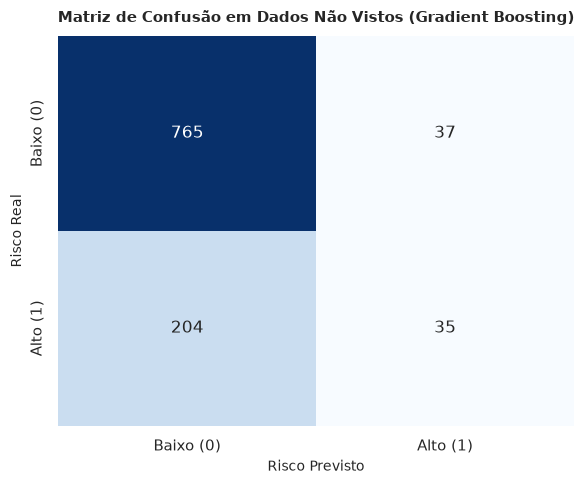

In [6]:
model_eval = models[best_model_name](BASE_RANDOM_SEED)
eval_res = evaluate_unseen_data(model_eval, X_dev, y_dev, X_test, y_test)

model_m = eval_res["model_metrics"]
base_m = eval_res["baseline_metrics"]

print("=== DESEMPENHO EM DADOS NÃO VISTOS (2026) ===")
print(f"Modelo: {best_model_name}")
print(f"  Acurácia:                 {model_m['Acurácia']*100:.2f}%")
print(f"  F1-Score:                 {model_m['F1_Score']:.4f}")
print(f"  Precisão (Classe Risco):  {model_m['Precisão_Classe_1']*100:.2f}%")
print(f"  Recall (Classe Risco):    {model_m['Recall_Classe_1']*100:.2f}%")
if model_m['ROC_AUC'] is not None:
    print(f"  ROC-AUC:                  {model_m['ROC_AUC']:.4f}")

print("\n=== CONFRONTO COM O BASELINE DA CLASSE MAJORITÁRIA ===")
print(f"  Acurácia Baseline Dummy:  {base_m['Acurácia']*100:.2f}%")
print(f"  F1-Score Baseline Dummy:  {base_m['F1_Score']:.4f}")

# Matriz de confusão
fig_cm = plot_confusion_matrix(eval_res["confusion_matrix"], model_name=best_model_name)
plt.show()

# Auditoria quantitativa de Concept Drift
drift_audit = analyze_concept_drift(df_dev, df_test)
print("\n=== AUDITORIA DE CONCEPT DRIFT ===")
print(f"Volume médio de crimes/janela em Dev (2022-2025):  {drift_audit['dev_crimes_mean_per_window']:.2f}")
print(f"Volume médio de crimes/janela em Teste (2026):     {drift_audit['test_crimes_mean_per_window']:.2f}")
print(f"Variação na densidade criminal:                     {drift_audit['crime_volume_drift_pct']:.1f}%")
print(f"Prevalência de Risco Alto:                          Dev={drift_audit['dev_high_risk_prevalence_pct']:.1f}% vs Teste={drift_audit['test_high_risk_prevalence_pct']:.1f}%")

## Passo 7 do Enunciado: Treinamento da Versão Final para Deploy

Conforme estabelecido pelo enunciado acadêmico:
> *"Utilize todos os dados disponíveis (treino + validação + teste) para treinar a versão definitiva do modelo que será entregue ou implantada."*

O classificador vencedor é treinado sobre a totalidade do histórico ($X_{dev} \cup X_{test}$) e serializado em formato `.joblib`.

In [7]:
X_full = pd.concat([X_dev, X_test], ignore_index=True)
y_full = pd.concat([y_dev, y_test], ignore_index=True)

final_model_path = MODELS_FINAL_DIR / FINAL_MODEL_NAME
final_model = train_final_model(
    models[best_model_name],
    X_full,
    y_full,
    seed=BASE_RANDOM_SEED,
    export_path=final_model_path,
)

print(f"Artefato final de produção serializado em: {final_model_path.resolve()}")

# Teste de inferência operacional
amostra_teste = X_test.iloc[[0]]
resultado_inferencia = format_risk_prediction(final_model, amostra_teste)
print(f"Simulação de predição operacional em tempo real:\n{resultado_inferencia}")

Artefato final de produção serializado em: D:\Documentos\Github\spoincd-projeto-final\models\final\modelo_risco_ifsp_final.joblib
Simulação de predição operacional em tempo real:
{'predicao_classe': 0, 'classificacao_risco': 'Risco Baixo', 'probabilidade_risco_alto': 0.1292783691185199}
